# Imports

In [1]:
!pip install -q transformers

In [2]:
import gc
import json
import re
import time
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from datasets import load_dataset
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score, RocCurveDisplay)
from IPython.display import display

from transformers import AutoTokenizer


/home/azavgorodnev/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
SEED = 42
EPOCHS = 8
BATCH_SIZE = 128
MAX_LENGTH = 64
EMBED_DIM = 128
UNITS = 96
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ARTIFACTS = Path('01A_GRU_LSTM_rerun_artifacts')
ARTIFACTS.mkdir(exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything()
if DEVICE.type == 'cpu':
    torch.set_num_threads(min(4, torch.get_num_threads()))
print('PyTorch:', torch.__version__, 'Device:', DEVICE)

PyTorch: 2.11.0+cu128 Device: cuda


# Dataset

Load the dataset (we will be using [go_emotions](https://huggingface.co/datasets/google-research-datasets/go_emotions)). Pretokenize data or make a loader that tokenizes the sentenses as you iterate through the dataset. Implement two datasets: variable and fixed sentence length (in tokens). Don't forget to split the dataset into train and test subsets

In [4]:
dataset = load_dataset('google-research-datasets/go_emotions', name='raw', split='train')


In [5]:
emotions = ['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring',
    'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust',
    'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love',
    'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse',
    'sadness', 'surprise', 'neutral']


In [6]:
tokenizer = AutoTokenizer.from_pretrained('gpt2')
tokenizer.pad_token = tokenizer.eos_token


Строк raw: 211225 Уникальных ID: 58011
После агрегации: 54263


,texts,labels_per_text
train,43412.0,1.176656
val,5418.0,1.177003
test,5433.0,1.169520


,train,val,test
admiration,4135,481,506
amusement,2320,288,287
anger,1554,202,204
annoyance,2435,323,335
approval,2977,351,359
caring,1098,120,157
confusion,1331,173,169
curiosity,2176,276,271
desire,617,102,82
disappointment,1292,136,155


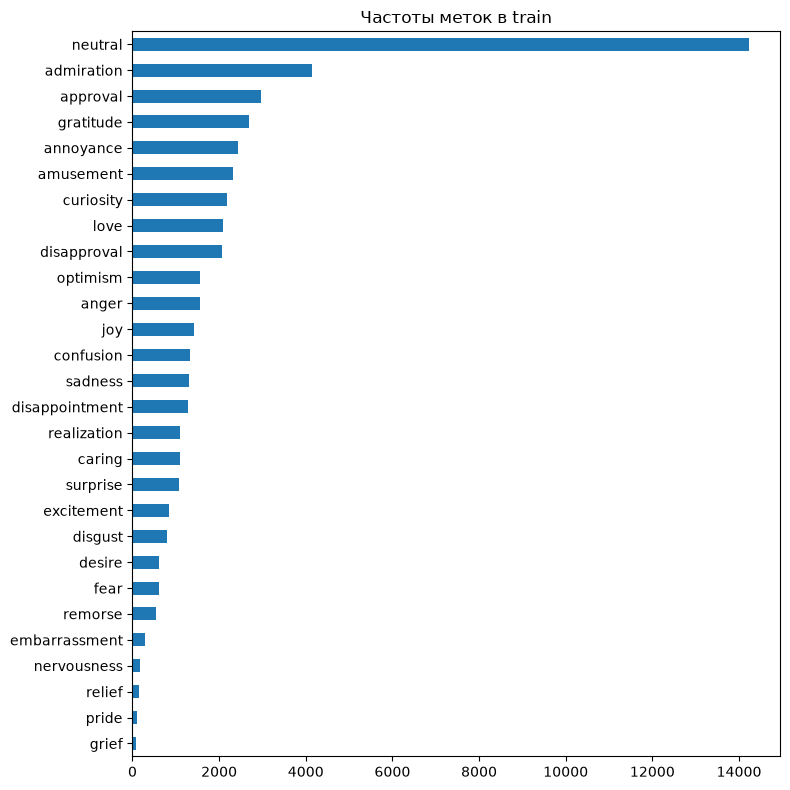

fixed позиций в padded-тензорах validation: 346752
variable позиций в padded-тензорах validation: 214760


('01A_GRU_LSTM_rerun_artifacts/tokenizer/tokenizer_config.json',
 '01A_GRU_LSTM_rerun_artifacts/tokenizer/tokenizer.json')

In [7]:
raw = dataset.select_columns(['id', 'text', 'rater_id', 'example_very_unclear', *emotions]).to_pandas()
print('Строк raw:', len(raw), 'Уникальных ID:', raw.id.nunique())

def normalize_text(text):
    return re.sub(r'\s+', ' ', str(text).lower()).strip()

def aggregate_annotations(raw):
    valid = raw.loc[~raw['example_very_unclear'].astype(bool)].copy()
    valid = valid.dropna(subset=['id', 'text']).drop_duplicates(['id', 'rater_id'])
    assert valid.groupby('id')['text'].nunique().max() == 1
    votes = valid.groupby('id', sort=True)[emotions].sum()
    texts = valid.groupby('id', sort=True)['text'].first()
    frame = texts.to_frame().join((votes >= 2).astype('float32'))
    frame['group'] = frame.text.map(normalize_text)
    frame = frame.loc[(frame[emotions].sum(axis=1) > 0) & frame.group.ne('')]
    return frame.reset_index()

frame = aggregate_annotations(raw)
train_idx, rest_idx = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=SEED)
                          .split(frame, groups=frame.group))
rest = frame.iloc[rest_idx]
val_rel, test_rel = next(GroupShuffleSplit(n_splits=1, test_size=.5, random_state=SEED)
                        .split(rest, groups=rest.group))
splits = {'train': frame.iloc[train_idx].reset_index(drop=True),
          'val': rest.iloc[val_rel].reset_index(drop=True),
          'test': rest.iloc[test_rel].reset_index(drop=True)}
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    assert set(splits[a].id).isdisjoint(splits[b].id)
    assert set(splits[a].group).isdisjoint(splits[b].group)
for part, df in splits.items():
    df[['id']].to_csv(ARTIFACTS / f'{part}_ids.csv', index=False)
print('После агрегации:', len(frame))
display(pd.DataFrame({part: {'texts': len(df), 'labels_per_text': df[emotions].sum(axis=1).mean()}
                      for part, df in splits.items()}).T)
support = pd.DataFrame({part: df[emotions].sum().astype(int) for part, df in splits.items()})
display(support)
support['train'].sort_values().plot.barh(figsize=(8, 8), title='Частоты меток в train')
plt.tight_layout(); plt.show()
del raw, dataset


def encode(text, max_length=MAX_LENGTH):
    ids = tokenizer.encode(text, add_special_tokens=False, truncation=True, max_length=max_length)
    return ids or [tokenizer.eos_token_id]

encoded = {part: [encode(text) for text in df.text] for part, df in splits.items()}
y = {part: df[emotions].to_numpy(dtype=np.float32) for part, df in splits.items()}
class EmotionDataset(Dataset):
    def __init__(self, sequences, labels, variant):
        self.sequences = sequences
        self.labels = labels
        self.variant = variant

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, index):
        seq = self.sequences[index]
        length = len(seq)
        if self.variant == 'fixed':
            seq = seq + [tokenizer.pad_token_id] * (MAX_LENGTH - length)
        return (torch.tensor(seq, dtype=torch.long), length,
                torch.tensor(self.labels[index], dtype=torch.float32))

def collate_batch(batch):
    tokens, lengths, labels = zip(*batch)
    return (pad_sequence(tokens, batch_first=True, padding_value=tokenizer.pad_token_id),
            torch.tensor(lengths, dtype=torch.long), torch.stack(labels))

def make_loader(part, variant, training=False):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(EmotionDataset(encoded[part], y[part], variant),
        batch_size=BATCH_SIZE, shuffle=training, collate_fn=collate_batch,
        num_workers=0, generator=generator, pin_memory=DEVICE.type == 'cuda')

for variant in ['fixed', 'variable']:
    positions = sum(tokens.numel() for tokens, _, _ in make_loader('val', variant))
    print(variant, 'позиций в padded-тензорах validation:', positions)

tokenizer.save_pretrained(ARTIFACTS / 'tokenizer')


In [8]:
samples = splits['train'].sample(n=min(8, len(splits['train'])))
for _, sample in samples.iterrows():
    labels = [emotion for emotion in emotions if sample[emotion] == 1]
    print(f"ID: {sample['id']}")
    print(sample['text'])
    print('Emotions:', ', '.join(labels))
    print('-' * 80)


ID: ee195qe
Have a good day at work bud
Emotions: caring
--------------------------------------------------------------------------------
ID: ed8jdcf
Very surprised he didn't frog leap at the guy the close the distance
Emotions: surprise
--------------------------------------------------------------------------------
ID: ee626do
So we are homicidal manics until we get bored and then follow the road rules for fun.
Emotions: amusement
--------------------------------------------------------------------------------
ID: edss7ih
Absolutely. I'd love it. No matter how much I like the guy, if he just goes for it that's not cool.
Emotions: excitement, love
--------------------------------------------------------------------------------
ID: ed27uml
I have failed you [NAME]. I have failed you.
Emotions: anger
--------------------------------------------------------------------------------
ID: ef02r5k
I LOVE [NAME]!!! She’s all around a really outstanding and kind human being
Emotions: admiration

# Model

Implement your model. The model should have the RNN architecture (with LSTM or GRU cells), support stacking and bidirectional feature extraction.

In [9]:
def get_name(prefix: str | None = None, suffix: str | None = None, separator: str = '_') -> str | None:
    return prefix and prefix + separator + suffix or suffix or None

In [10]:
class GRUCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.input_linear = nn.Linear(input_size, 3 * hidden_size)
        self.hidden_linear = nn.Linear(hidden_size, 3 * hidden_size)
        bound = hidden_size ** -0.5
        for parameter in self.parameters():
            nn.init.uniform_(parameter, -bound, bound)

    def forward(self, x, h):
        x_r, x_z, x_n = self.input_linear(x).chunk(3, dim=-1)
        h_r, h_z, h_n = self.hidden_linear(h).chunk(3, dim=-1)
        r = torch.sigmoid(x_r + h_r)
        z = torch.sigmoid(x_z + h_z)
        n = torch.tanh(x_n + r * h_n)
        return (1 - z) * n + z * h


class EmotionRNN(nn.Module):
    cell_class = GRUCell
    rnn_name = 'GRU'

    def __init__(self, n_tokens, n_labels, units=96, embed_dim=128,
                 n_stacks=1, bidirectional=False, dropout=.3,
                 padding_idx=50256):
        super().__init__()
        self.units = units
        self.directions = 2 if bidirectional else 1
        self.embedding = nn.Embedding(n_tokens, embed_dim, padding_idx=padding_idx)
        self.layers = nn.ModuleList()
        for layer_index in range(n_stacks):
            input_size = embed_dim if layer_index == 0 else units * self.directions
            self.layers.append(nn.ModuleList([
                self.cell_class(input_size, units) for _ in range(self.directions)
            ]))
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(units * self.directions, n_labels)

    def run_direction(self, cell, sequence, lengths, reverse=False):
        batch_size, steps, _ = sequence.shape
        h = sequence.new_zeros(batch_size, self.units)
        outputs = [None] * steps
        indices = range(steps - 1, -1, -1) if reverse else range(steps)
        for t in indices:
            active = (t < lengths).unsqueeze(1)
            next_h = cell(sequence[:, t], h)
            h = torch.where(active, next_h, h)
            outputs[t] = torch.where(active, h, torch.zeros_like(h))
        return torch.stack(outputs, dim=1), h

    def forward(self, tokens, lengths):
        lengths = lengths.to(tokens.device)
        sequence = self.embedding(tokens)
        for layer in self.layers:
            outputs, final_states = [], []
            for direction, cell in enumerate(layer):
                output, h = self.run_direction(cell, sequence, lengths,
                                               reverse=direction == 1)
                outputs.append(output)
                final_states.append(h)
            sequence = torch.cat(outputs, dim=-1)
        features = torch.cat(final_states, dim=-1)
        return self.classifier(self.dropout(features))


def get_model(units, n_tokens, n_labels, n_stacks=1, bidirectional=False,
              name=None):
    model = EmotionRNN(n_tokens, n_labels, units=units, embed_dim=EMBED_DIM,
        n_stacks=n_stacks, bidirectional=bidirectional,
        padding_idx=tokenizer.pad_token_id)
    model.name = name
    return model


# Training

Train several models on the two dataset variants. Use either of the cell types (LSTM or GRU)
* Simple RNN (no stacking, one direction)
* Stacked RNN (stacking, one direction)
* Bidirectional RNN (no stacking, bidirectional)
* Stacked Bidirectional RNN (stacking, bidirectional)

In [11]:
architectures = [dict(arch='simple', n_stacks=1, bidirectional=False),
                dict(arch='stacked', n_stacks=2, bidirectional=False),
                dict(arch='bidirectional', n_stacks=1, bidirectional=True),
                dict(arch='stacked_bidirectional', n_stacks=2, bidirectional=True)]

variants = ['fixed', 'variable']


Which loss should be used to multilabel classification? Which metrics?

In [12]:
def macro_auc(target, prob):
    valid = (target.sum(axis=0) > 0) & (target.sum(axis=0) < len(target))
    return float(np.mean([roc_auc_score(target[:, i], prob[:, i])
                          for i in np.flatnonzero(valid)])) if valid.any() else float('nan')

@torch.inference_mode()
def predict_loader(model, loader):
    model.eval()
    probabilities = []
    for tokens, lengths, _ in loader:
        logits = model(tokens.to(DEVICE), lengths)
        probabilities.append(torch.sigmoid(logits).cpu().numpy())
    return np.concatenate(probabilities)

@torch.inference_mode()
def validation_loss(model, loader, criterion):
    model.eval()
    total, count = 0., 0
    for tokens, lengths, labels in loader:
        logits = model(tokens.to(DEVICE), lengths)
        loss = criterion(logits, labels.to(DEVICE))
        total += loss.item() * len(labels)
        count += len(labels)
    return total / count

def load_model(path, model_class=EmotionRNN):
    checkpoint = torch.load(path, map_location='cpu', weights_only=True)
    model = model_class(**checkpoint['model_config'])
    model.load_state_dict(checkpoint['state_dict'])
    return model.to(DEVICE).eval()

def train_run(config, variant, model_class=EmotionRNN):
    seed_everything()
    name = get_name(get_name(variant, config['arch']), model_class.rnn_name)
    model_config = dict(n_tokens=len(tokenizer), n_labels=len(emotions), units=UNITS,
        embed_dim=EMBED_DIM, n_stacks=config['n_stacks'],
        bidirectional=config['bidirectional'], padding_idx=tokenizer.pad_token_id)
    model = model_class(**model_config).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.BCEWithLogitsLoss()
    train_loader = make_loader('train', variant, training=True)
    val_loader = make_loader('val', variant)
    history = {'loss': [], 'val_loss': []}
    best_loss, bad_epochs, best_state, best_epoch = float('inf'), 0, None, 0
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for epoch in range(EPOCHS):
        model.train()
        total, count = 0., 0
        for tokens, lengths, labels in train_loader:
            tokens, labels = tokens.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(tokens, lengths)
            loss = criterion(logits, labels)
            if not torch.isfinite(loss):
                raise RuntimeError(f'Non-finite loss in {name}')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1., error_if_nonfinite=True)
            optimizer.step()
            total += loss.item() * len(labels)
            count += len(labels)
        train_loss = total / count
        val_loss = validation_loss(model, val_loader, criterion)
        if not np.isfinite(val_loss):
            raise RuntimeError(f'Non-finite validation loss in {name}')
        history['loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        print(f'{name} | epoch {epoch + 1}/{EPOCHS} | '
              f'train BCE={train_loss:.4f} | val BCE={val_loss:.4f}')
        if val_loss < best_loss:
            best_loss, bad_epochs, best_epoch = val_loss, 0, epoch + 1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= 2:
                print('Early stopping')
                break
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    model.load_state_dict(best_state)
    prob = predict_loader(model, val_loader)
    threshold = 0.5
    path = ARTIFACTS / f'{name}.pt'
    torch.save({'state_dict': best_state, 'model_config': model_config,
        'threshold': threshold, 'tokenizer': 'gpt2', 'emotions': emotions,
        'max_length': MAX_LENGTH, 'pad_token_id': tokenizer.pad_token_id,
        'best_epoch': best_epoch, 'seed': SEED}, path)
    pd.DataFrame(history).to_csv(ARTIFACTS / f'{name}_history.csv', index=False)
    run = dict(name=name, variant=variant, config=dict(config), path=str(path),
        threshold=threshold, val_auc=macro_auc(y['val'], prob),
        val_f1=f1_score(y['val'], prob >= threshold, average='micro', zero_division=0),
        seconds=seconds, parameters=sum(p.numel() for p in model.parameters()),
        epochs=len(history['loss']), best_epoch=best_epoch, history=history)
    del model, optimizer
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return run


In [13]:
runs = []
for variant in ['fixed', 'variable']:
    for config in architectures:
        runs.append(train_run(config, variant))
        (ARTIFACTS / 'runs.json').write_text(json.dumps(runs, indent=2), encoding='utf-8')
validation_table = pd.DataFrame([{k: r[k] for k in
    ['name', 'val_auc', 'val_f1', 'threshold', 'seconds', 'parameters', 'epochs', 'best_epoch']} for r in runs])
display(validation_table.sort_values('val_auc', ascending=False))
best_gru = max(runs, key=lambda r: r['val_auc'] if np.isfinite(r['val_auc']) else -np.inf)
print('Лучшая GRU по validation:', best_gru['name'])


fixed_simple_GRU | epoch 1/8 | train BCE=0.1826 | val BCE=0.1479
fixed_simple_GRU | epoch 2/8 | train BCE=0.1477 | val BCE=0.1434
fixed_simple_GRU | epoch 3/8 | train BCE=0.1417 | val BCE=0.1357
fixed_simple_GRU | epoch 4/8 | train BCE=0.1332 | val BCE=0.1286
fixed_simple_GRU | epoch 5/8 | train BCE=0.1268 | val BCE=0.1238
fixed_simple_GRU | epoch 6/8 | train BCE=0.1221 | val BCE=0.1210
fixed_simple_GRU | epoch 7/8 | train BCE=0.1182 | val BCE=0.1187
fixed_simple_GRU | epoch 8/8 | train BCE=0.1146 | val BCE=0.1170
fixed_stacked_GRU | epoch 1/8 | train BCE=0.1753 | val BCE=0.1492
fixed_stacked_GRU | epoch 2/8 | train BCE=0.1499 | val BCE=0.1465
fixed_stacked_GRU | epoch 3/8 | train BCE=0.1438 | val BCE=0.1378
fixed_stacked_GRU | epoch 4/8 | train BCE=0.1371 | val BCE=0.1334
fixed_stacked_GRU | epoch 5/8 | train BCE=0.1328 | val BCE=0.1298
fixed_stacked_GRU | epoch 6/8 | train BCE=0.1288 | val BCE=0.1265
fixed_stacked_GRU | epoch 7/8 | train BCE=0.1244 | val BCE=0.1235
fixed_stacked_GRU 

,name,val_auc,val_f1,threshold,seconds,parameters,epochs,best_epoch
2,fixed_bidirectional_GRU,0.827729,0.455607,0.5,261.157148,6568476,8,7
6,variable_bidirectional_GRU,0.827729,0.455607,0.5,162.705682,6568476,8,7
3,fixed_stacked_bidirectional_GRU,0.823358,0.436897,0.5,459.413319,6735516,7,5
7,variable_stacked_bidirectional_GRU,0.823358,0.436897,0.5,275.228770,6735516,7,5
0,fixed_simple_GRU,0.766190,0.380815,0.5,141.477739,6500700,8,8
4,variable_simple_GRU,0.766190,0.380815,0.5,90.446611,6500700,8,8
1,fixed_stacked_GRU,0.740283,0.348500,0.5,268.338276,6556572,8,8
5,variable_stacked_GRU,0.736789,0.294132,0.5,165.715860,6556572,8,7


Лучшая GRU по validation: fixed_bidirectional_GRU


# Evaluation

Evaluate the models you trained on the test datasets. Plot ROC curves for each label (use `sklearn.metrics.RocCurveDisplay`) for each model.

In [14]:
def evaluate_probabilities(target, prob, threshold=0.5):
    pred = prob >= threshold
    return {'micro_f1': f1_score(target, pred, average='micro', zero_division=0),
            'macro_f1': f1_score(target, pred, average='macro', zero_division=0),
            'precision': precision_score(target, pred, average='micro', zero_division=0),
            'recall': recall_score(target, pred, average='micro', zero_division=0),
            'macro_roc_auc': macro_auc(target, prob)}

def plot_roc_curve(X, y, model, ax=None):
    prob = predict_loader(model, X)
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 7))
    label_auc = [(i, roc_auc_score(y[:, i], prob[:, i]))
                 for i in range(len(emotions)) if np.unique(y[:, i]).size == 2]
    label_auc.sort(key=lambda item: item[1], reverse=True)
    for i, auc in label_auc:
        RocCurveDisplay.from_predictions(y[:, i], prob[:, i], name=emotions[i], ax=ax)
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1)
    ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=7)
    return macro_auc(y, prob)


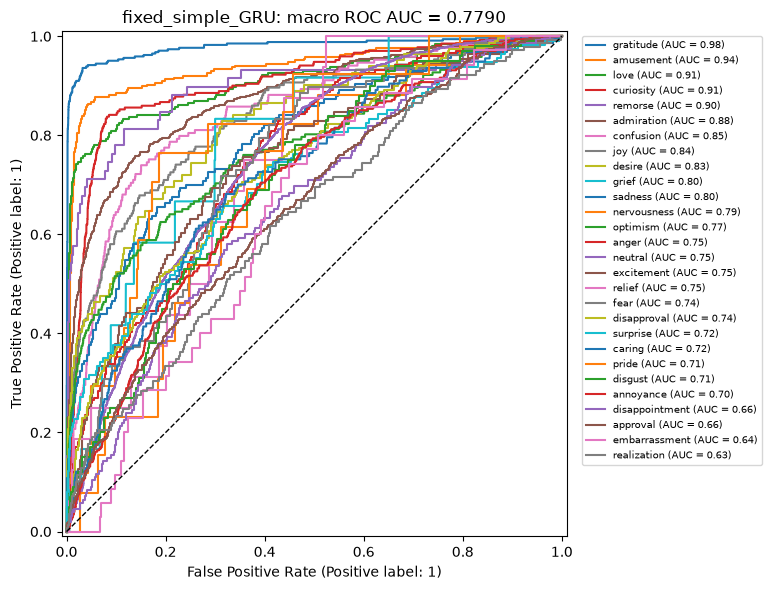

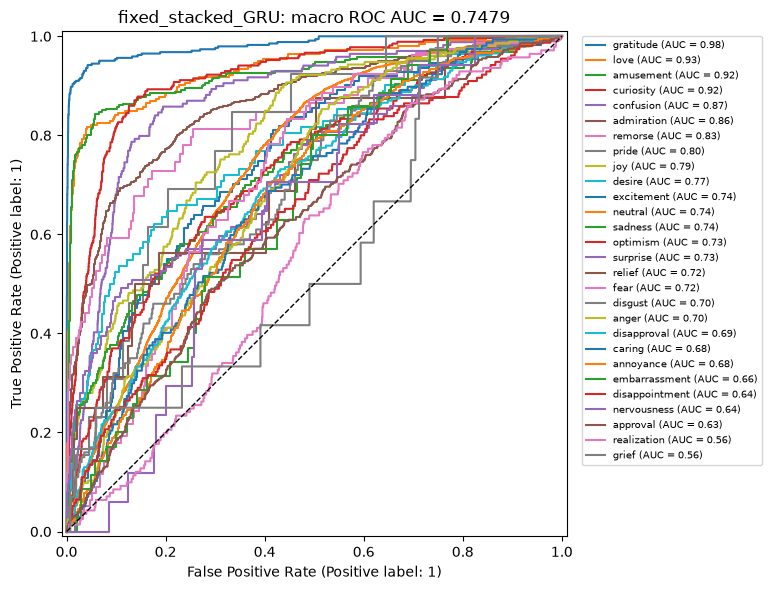

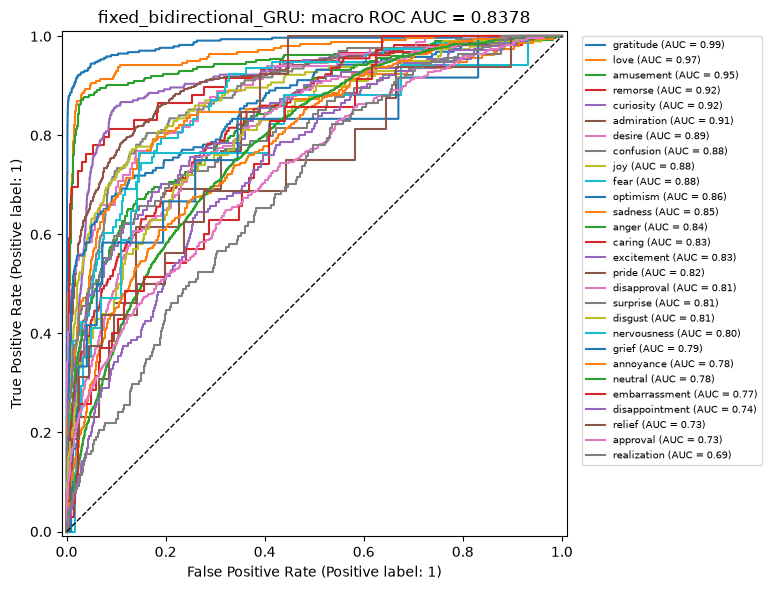

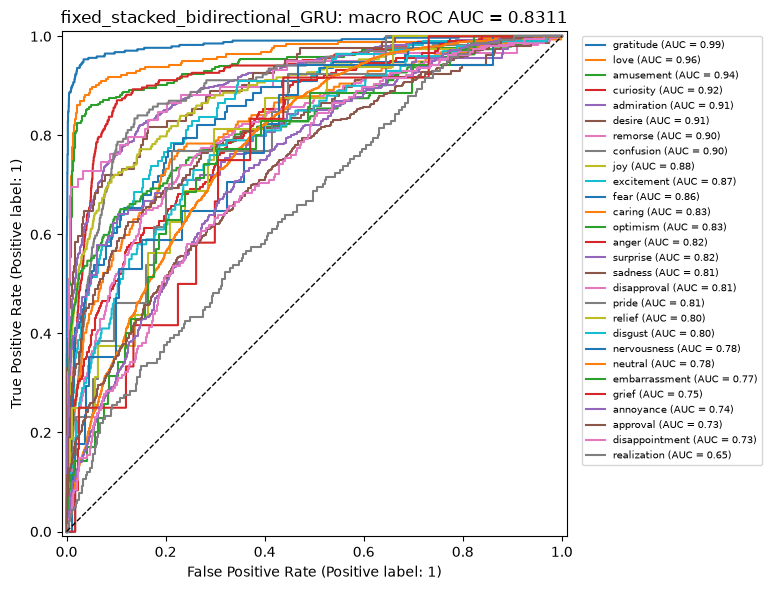

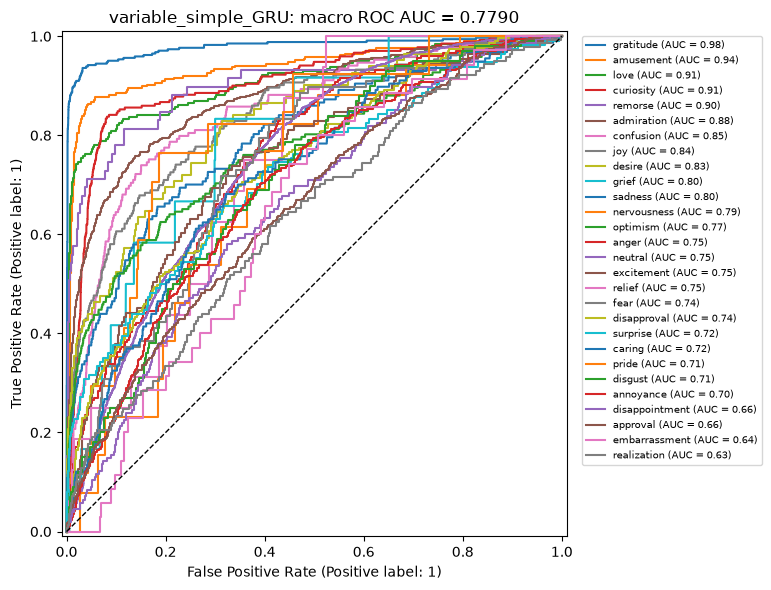

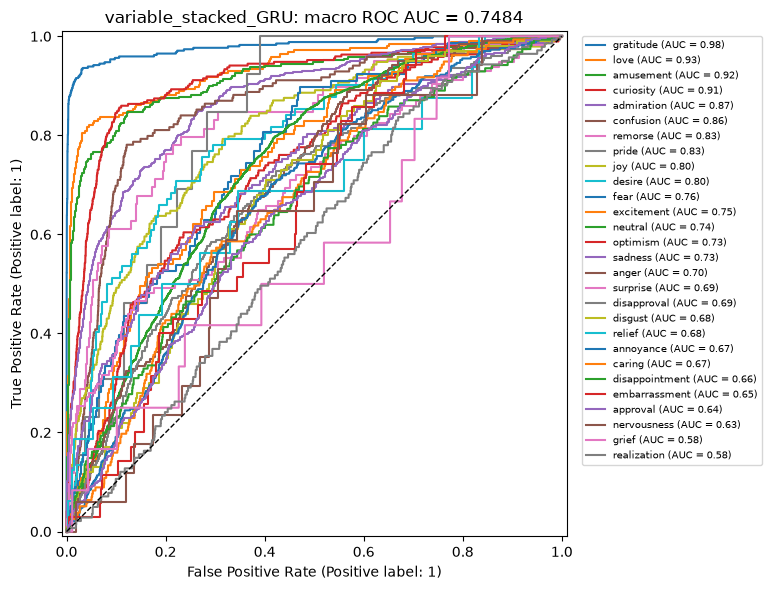

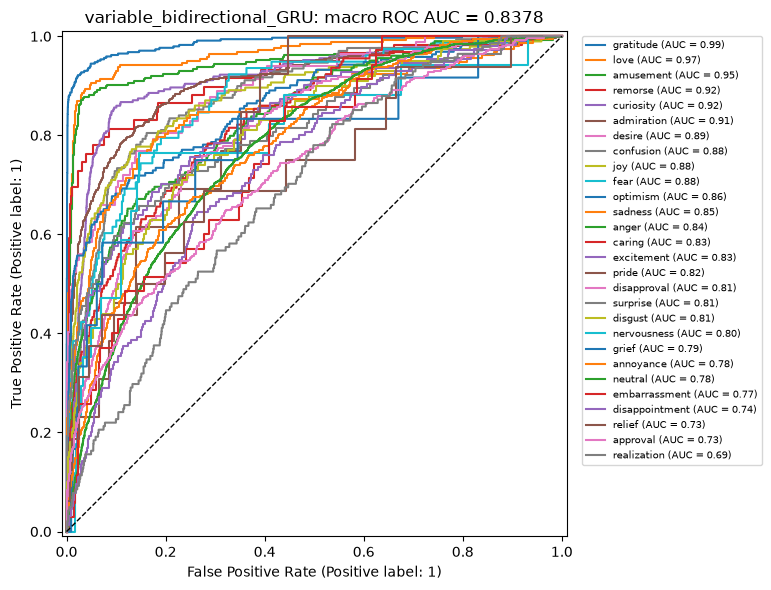

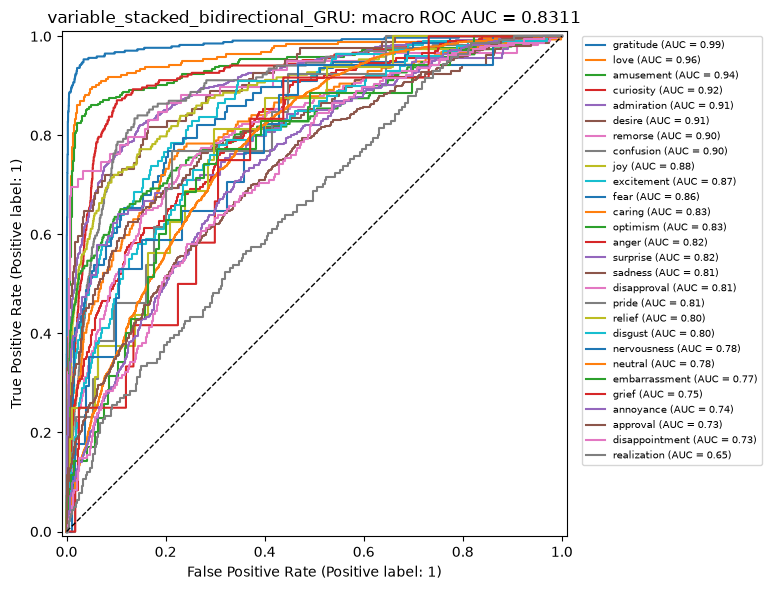

,micro_f1,macro_f1,precision,recall,macro_roc_auc
name,,,,,
fixed_simple_GRU,0.3860,0.1224,0.6500,0.2745,0.7790
fixed_stacked_GRU,0.3401,0.0799,0.5817,0.2403,0.7479
fixed_bidirectional_GRU,0.4612,0.2302,0.6718,0.3511,0.8378
fixed_stacked_bidirectional_GRU,0.4314,0.2055,0.6826,0.3154,0.8311
variable_simple_GRU,0.3860,0.1224,0.6500,0.2745,0.7790
variable_stacked_GRU,0.2834,0.0502,0.5917,0.1863,0.7484
variable_bidirectional_GRU,0.4612,0.2302,0.6718,0.3511,0.8378
variable_stacked_bidirectional_GRU,0.4314,0.2055,0.6826,0.3154,0.8311


In [15]:
rows, test_probabilities = [], {}
for run in runs:
    model = load_model(run['path'])
    prob = predict_loader(model, make_loader('test', run['variant']))
    assert prob.shape == y['test'].shape and np.isfinite(prob).all()
    test_probabilities[run['name']] = prob
    rows.append({'name': run['name'], **evaluate_probabilities(y['test'], prob, run['threshold'])})
    fig, ax = plt.subplots(figsize=(10, 6))
    auc = plot_roc_curve(make_loader('test', run['variant']), y['test'], model, ax)
    ax.set_title(f"{run['name']}: macro ROC AUC = {auc:.4f}")
    fig.tight_layout(); fig.savefig(ARTIFACTS / f"{run['name']}_roc.png", bbox_inches='tight')
    plt.show()
    del model
    gc.collect()

results = pd.DataFrame(rows).set_index('name')
results.to_csv(ARTIFACTS / 'test_metrics.csv')
display(results.round(4))


Plot the mean ROC AUC scores. Which model has the highest score? On what kind of dataset?

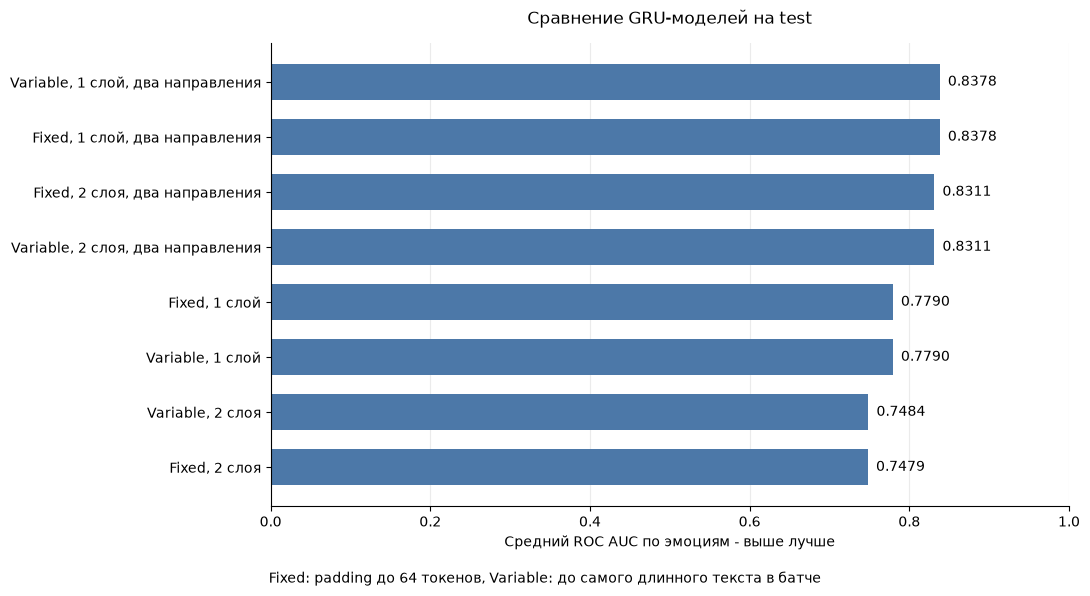

Лучший test ROC AUC: variable_bidirectional_GRU - 0.8378


Для примеров и бонуса выбрана по validation: fixed_bidirectional_GRU


In [16]:
scores = results['macro_roc_auc'].sort_values()
labels = {
    'fixed_simple_GRU': 'Fixed, 1 слой',
    'fixed_stacked_GRU': 'Fixed, 2 слоя',
    'fixed_bidirectional_GRU': 'Fixed, 1 слой, два направления',
    'fixed_stacked_bidirectional_GRU': 'Fixed, 2 слоя, два направления',
    'variable_simple_GRU': 'Variable, 1 слой',
    'variable_stacked_GRU': 'Variable, 2 слоя',
    'variable_bidirectional_GRU': 'Variable, 1 слой, два направления',
    'variable_stacked_bidirectional_GRU': 'Variable, 2 слоя, два направления',
}
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh([labels.get(name, name) for name in scores.index], scores.values,
               color='#4C78A8', height=0.65)
ax.bar_label(bars, labels=[f'{value:.4f}' for value in scores], padding=6)
ax.set_xlim(0, 1)
ax.set_xlabel('Средний ROC AUC по эмоциям - выше лучше')
ax.set_title('Сравнение GRU-моделей на test', pad=14)
ax.set_axisbelow(True)
ax.grid(axis='x', alpha=0.25)
ax.spines[['top', 'right']].set_visible(False)
fig.text(0.5, 0.02, 'Fixed: padding до 64 токенов, Variable: до самого длинного текста в батче',
         ha='center', fontsize=10)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()
leader = scores.idxmax()
print(f'Лучший test ROC AUC: {leader} - {scores.loc[leader]:.4f}')
print('Для примеров и бонуса выбрана по validation:', best_gru['name'])


Inspect the best model performance closer. Come up with some sentences (in English). Does the model output sensible results?

In [17]:
best_model = load_model(best_gru['path'])
@torch.inference_mode()
def predict_text(text, model, max_length=None):
    limit = MAX_LENGTH if max_length is None else max_length
    seq = encode(text, limit)
    model.eval()
    tokens = torch.tensor([seq], dtype=torch.long, device=DEVICE)
    lengths = torch.tensor([len(seq)], dtype=torch.long)
    return torch.sigmoid(model(tokens, lengths))[0].cpu().numpy()

def label_text(text, model, threshold=0.5, max_length=None):
    prob = predict_text(text, model, max_length)
    return [emotion for emotion, p in zip(emotions, prob) if p >= threshold]


In [18]:
def plot_emotion_scores(text, model, max_length=None, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 3))
    prob = predict_text(text, model, max_length)
    ax.bar(emotions, prob)
    ax.axhline(0.5, color='red', linestyle='--', label='threshold = 0.5')
    ax.set(title=text, ylabel='Probability', ylim=(0, 1))
    ax.tick_params(axis='x', rotation=90); ax.legend()
    return ax


For each of your texts get a list of emotion labels and plot emotion scores

Thank you so much for your help, I really appreciate it! : ['gratitude']


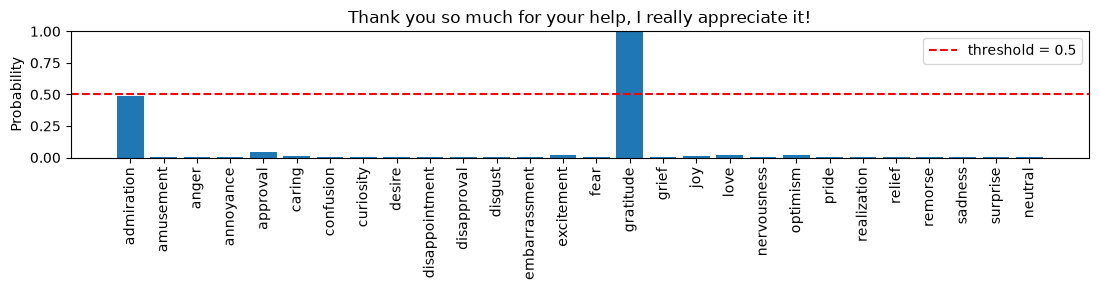

I am furious that you lied to me again. : []


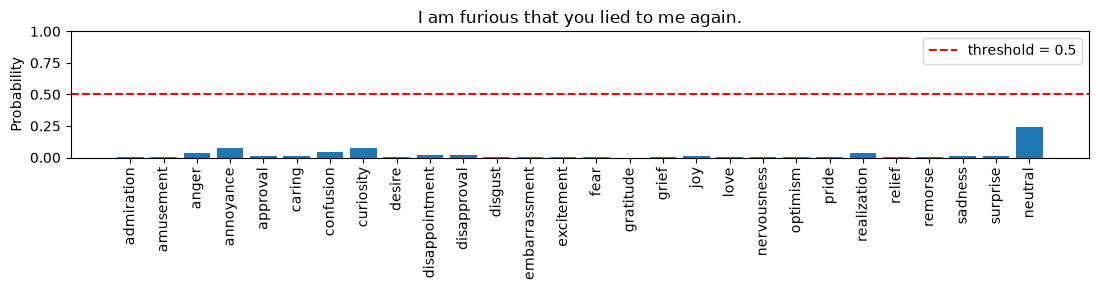

I miss my friend and feel so lonely. : ['sadness']


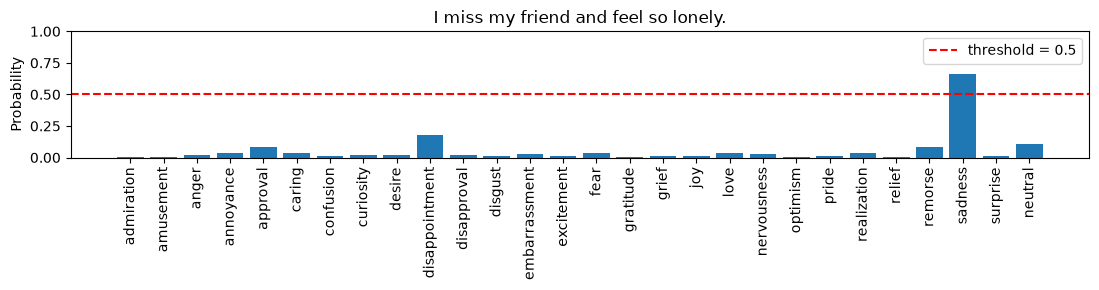

Why does this happen? I would like to understand. : []


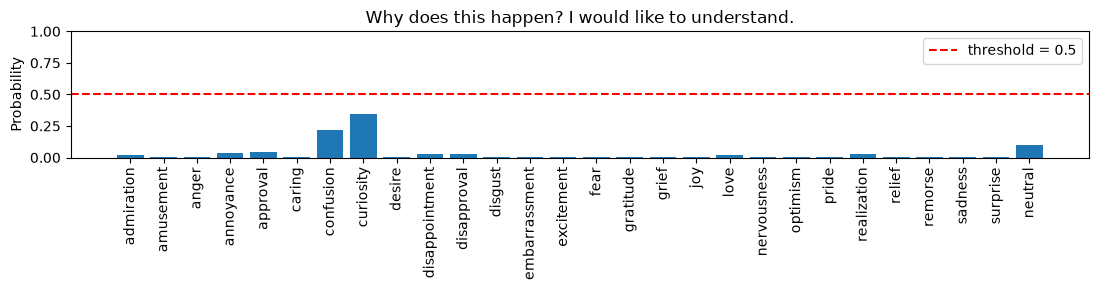

I am not happy about this at all. : []


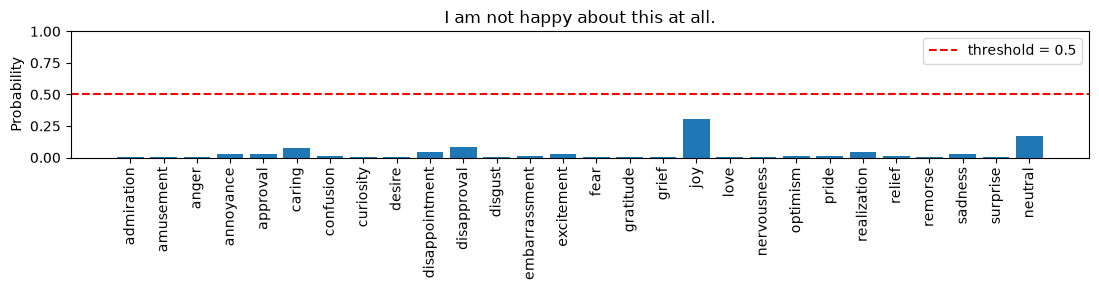

Great, another three hours stuck in traffic. Just what I needed. : ['admiration']


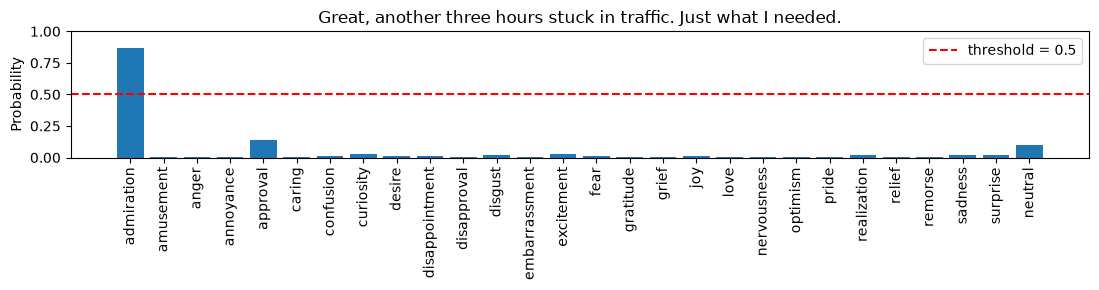

In [19]:
texts = ['Thank you so much for your help, I really appreciate it!',
         'I am furious that you lied to me again.',
         'I miss my friend and feel so lonely.',
         'Why does this happen? I would like to understand.',
         'I am not happy about this at all.',
         'Great, another three hours stuck in traffic. Just what I needed.']
for text in texts:
    print(text, ':', label_text(text, best_model))
    plot_emotion_scores(text, best_model)
    plt.tight_layout(); plt.show()


# Bonus

Train and evaluate the same model as your best one, but use a different cell type

fixed_bidirectional_LSTM | epoch 1/8 | train BCE=0.1775 | val BCE=0.1416
fixed_bidirectional_LSTM | epoch 2/8 | train BCE=0.1366 | val BCE=0.1292
fixed_bidirectional_LSTM | epoch 3/8 | train BCE=0.1250 | val BCE=0.1213
fixed_bidirectional_LSTM | epoch 4/8 | train BCE=0.1161 | val BCE=0.1157
fixed_bidirectional_LSTM | epoch 5/8 | train BCE=0.1087 | val BCE=0.1121
fixed_bidirectional_LSTM | epoch 6/8 | train BCE=0.1020 | val BCE=0.1107
fixed_bidirectional_LSTM | epoch 7/8 | train BCE=0.0961 | val BCE=0.1101
fixed_bidirectional_LSTM | epoch 8/8 | train BCE=0.0905 | val BCE=0.1111


,micro_f1,macro_f1,precision,recall,macro_roc_auc
fixed_bidirectional_GRU,0.4612,0.2302,0.6718,0.3511,0.8378
fixed_bidirectional_LSTM,0.4377,0.1808,0.6573,0.3281,0.8263


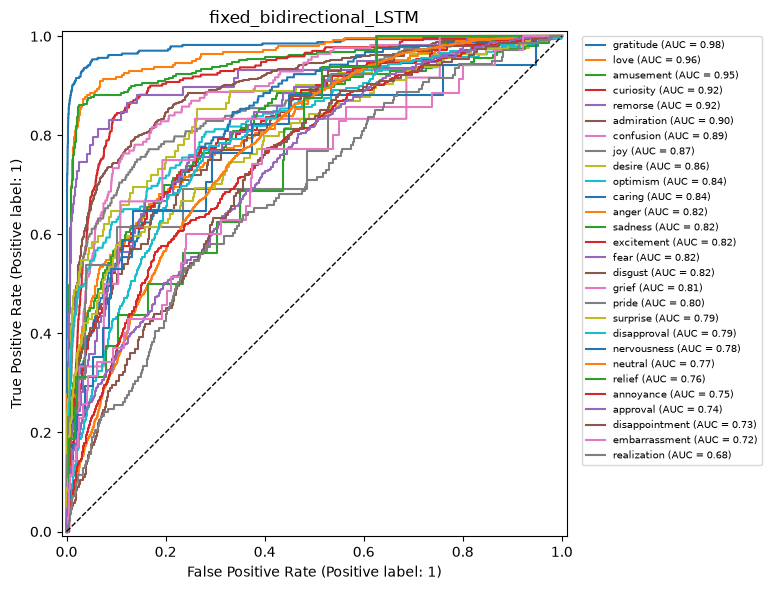

LSTM минус GRU:
micro_f1        -0.0234
macro_f1        -0.0494
precision       -0.0145
recall          -0.0230
macro_roc_auc   -0.0115
dtype: float64


In [20]:
class LSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.input_linear = nn.Linear(input_size, 4 * hidden_size)
        self.hidden_linear = nn.Linear(hidden_size, 4 * hidden_size)
        bound = hidden_size ** -0.5
        for parameter in self.parameters():
            nn.init.uniform_(parameter, -bound, bound)

    def forward(self, x, h, c):
        gates = self.input_linear(x) + self.hidden_linear(h)
        i, f, g, o = gates.chunk(4, dim=-1)
        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        g = torch.tanh(g)
        o = torch.sigmoid(o)
        c = f * c + i * g
        h = o * torch.tanh(c)
        return h, c


class EmotionLSTM(EmotionRNN):
    cell_class = LSTMCell
    rnn_name = 'LSTM'

    def run_direction(self, cell, sequence, lengths, reverse=False):
        batch_size, steps, _ = sequence.shape
        h = sequence.new_zeros(batch_size, self.units)
        c = sequence.new_zeros(batch_size, self.units)
        outputs = [None] * steps
        indices = range(steps - 1, -1, -1) if reverse else range(steps)
        for t in indices:
            active = (t < lengths).unsqueeze(1)
            next_h, next_c = cell(sequence[:, t], h, c)
            h = torch.where(active, next_h, h)
            c = torch.where(active, next_c, c)
            outputs[t] = torch.where(active, h, torch.zeros_like(h))
        return torch.stack(outputs, dim=1), h


bonus_run = train_run(best_gru['config'], best_gru['variant'], model_class=EmotionLSTM)
bonus_model = load_model(bonus_run['path'], model_class=EmotionLSTM)
bonus_prob = predict_loader(bonus_model, make_loader('test', bonus_run['variant']))
bonus_metrics = evaluate_probabilities(y['test'], bonus_prob)
comparison = pd.DataFrame({best_gru['name']: results.loc[best_gru['name']].to_dict(),
                           bonus_run['name']: bonus_metrics}).T
display(comparison.round(4))
comparison.to_csv(ARTIFACTS / 'bonus_comparison.csv')
fig, ax = plt.subplots(figsize=(10, 6))
plot_roc_curve(make_loader('test', bonus_run['variant']), y['test'], bonus_model, ax)
ax.set_title(bonus_run['name'])
plt.tight_layout(); plt.show()
print('LSTM минус GRU:')
print((comparison.iloc[1] - comparison.iloc[0]).round(4))
